In [2]:
from google.colab import drive, userdata
drive.mount('/content/drive')

token = userdata.get('GH_TOKEN')
![ -d /content/yuca_transfer ] || git clone https://{token}@github.com/Frank-Dev007/yuca_transfer.git /content/yuca_transfer
%cd /content/yuca_transfer
!git pull
!git config user.name "Frank García"
!git config user.email "frankgpernett2006@gmail.com"

!pip install -q imagehash
!python scripts/preparar_datos.py

Mounted at /content/drive
Cloning into '/content/yuca_transfer'...
remote: Enumerating objects: 31, done.
remote: Counting objects: 100% (31/31), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 31 (delta 7), reused 14 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (31/31), 71.53 KiB | 10.22 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/yuca_transfer
Already up to date.
Copiando desde Drive...
Tamaño del zip (MB): 1354.1
Contenido de data/: ['cassavaleafdata', 'cassavaleafdata.zip']


In [5]:
import pandas as pd
from pathlib import Path
from PIL import Image

ROOT = Path("data/cassavaleafdata")
EXT = {".jpg", ".jpeg", ".png"}

filas = []
for split in ["train", "validation", "test"]:
    for clase_dir in sorted(p for p in (ROOT / split).iterdir() if p.is_dir()):
        for f in sorted(clase_dir.iterdir()):
            if f.suffix.lower() in EXT:
                with Image.open(f) as im:
                    ancho, alto = im.size
                filas.append({"split": split, "clase": clase_dir.name,
                              "ruta": str(f), "ancho": ancho, "alto": alto})

df = pd.DataFrame(filas)
df.to_csv("results/inventario_imagenes.csv", index=False)
print("Total de imágenes:", len(df))
df.head()

Total de imágenes: 9430


,split,clase,ruta,ancho,alto
0,train,cbb,data/cassavaleafdata/train/cbb/train-cbb-0.jpg,666,500
1,train,cbb,data/cassavaleafdata/train/cbb/train-cbb-1.jpg,666,500
2,train,cbb,data/cassavaleafdata/train/cbb/train-cbb-10.jpg,500,500
3,train,cbb,data/cassavaleafdata/train/cbb/train-cbb-100.jpg,500,666
4,train,cbb,data/cassavaleafdata/train/cbb/train-cbb-101.jpg,500,500


In [6]:
print("Estadísticas de tamaño (píxeles):")
print(df[["ancho", "alto"]].describe().round(1))

print("\nTamaños más frecuentes (ancho x alto):")
print(df.groupby(["ancho", "alto"]).size().sort_values(ascending=False).head(10))

print("\nTamaño mediano por clase:")
print(df.groupby("clase")[["ancho", "alto"]].median())

Estadísticas de tamaño (píxeles):
        ancho    alto
count  9430.0  9430.0
mean    611.6   572.0
std     140.0   109.3
min     420.0   347.0
25%     500.0   500.0
50%     543.0   500.0
75%     666.0   666.0
max    1622.0  1240.0

Tamaños más frecuentes (ancho x alto):
ancho  alto
500    666     2369
888    500     1328
625    500     1073
666    500     1070
500    500      719
       888      512
499    500       46
623    500       18
887    500       16
523    500       14
dtype: int64

Tamaño mediano por clase:
         ancho   alto
clase                
cbb      500.0  500.0
cbsd     625.0  500.0
cgm      500.0  584.0
cmd      507.0  500.0
healthy  625.0  500.0


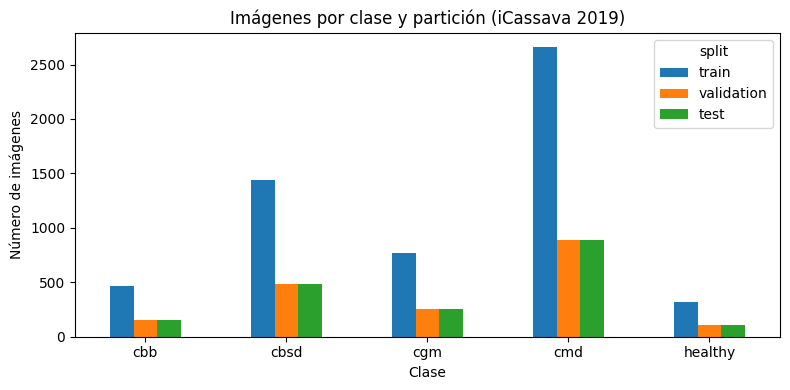

In [7]:
import matplotlib.pyplot as plt

tabla = df.groupby(["clase", "split"]).size().unstack()[["train", "validation", "test"]]
ax = tabla.plot(kind="bar", figsize=(8, 4))
ax.set_xlabel("Clase")
ax.set_ylabel("Número de imágenes")
ax.set_title("Imágenes por clase y partición (iCassava 2019)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("docs/evidencias/03_distribucion_clases.png", dpi=150)
plt.show()

In [8]:
clases = sorted(df.clase.unique())
fig, axes = plt.subplots(len(clases), 4, figsize=(12, 3 * len(clases)))
for i, c in enumerate(clases):
    muestras = df[(df.clase == c) & (df.split == "train")].sample(4, random_state=0)
    for j, ruta in enumerate(muestras.ruta):
        axes[i, j].imshow(Image.open(ruta))
        axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("docs/evidencias/04_ejemplos_por_clase.png", dpi=100)
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [10]:
import hashlib

def md5_archivo(ruta):
    with open(ruta, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["md5"] = df.ruta.apply(md5_archivo)
dup_exactos = df[df.duplicated("md5", keep=False)].sort_values("md5")
grupos_cruzados = dup_exactos.groupby("md5").split.nunique()

print("Imágenes que tienen al menos una copia exacta:", len(dup_exactos))
print("Grupos de copias que cruzan particiones:", int((grupos_cruzados > 1).sum()))
dup_exactos.to_csv("results/duplicados_exactos.csv", index=False)

Imágenes que tienen al menos una copia exacta: 68
Grupos de copias que cruzan particiones: 17


In [12]:
import imagehash
import numpy as np
from tqdm.auto import tqdm

def phash_bits(ruta):
    with Image.open(ruta) as im:
        return imagehash.phash(im).hash.flatten()

hashes = np.stack([phash_bits(r) for r in tqdm(df.ruta, desc="pHash")])
print("Forma de la matriz de huellas:", hashes.shape)

pHash:   0%|          | 0/9430 [00:00<?, ?it/s]

Forma de la matriz de huellas: (9430, 64)


In [13]:
def pares_cercanos(split_a, split_b, umbral):
    ia = np.where(df.split == split_a)[0]
    ib = np.where(df.split == split_b)[0]
    HB = hashes[ib]
    pares = []
    for k in range(0, len(ia), 200):
        bloque = ia[k:k + 200]
        d = (hashes[bloque][:, None, :] != HB[None, :, :]).sum(axis=2)
        fa, fb = np.where(d <= umbral)
        pares += [(bloque[x], ib[y], int(d[x, y])) for x, y in zip(fa, fb)]
    return pares

UMBRAL = 0   # empezar con 0; luego el equipo decide si prueba otro valor

resultados = []
for a, b in [("test", "train"), ("validation", "train"), ("test", "validation")]:
    pares = pares_cercanos(a, b, UMBRAL)
    print(f"{a} vs {b}: {len(pares)} pares con distancia <= {UMBRAL}")
    resultados += [{"particion_a": a, "ruta_a": df.ruta[i], "clase_a": df.clase[i],
                    "particion_b": b, "ruta_b": df.ruta[j], "clase_b": df.clase[j],
                    "distancia": d} for i, j, d in pares]

pd.DataFrame(resultados).to_csv(f"results/duplicados_phash_umbral{UMBRAL}.csv", index=False)

test vs train: 17 pares con distancia <= 0
validation vs train: 14 pares con distancia <= 0
test vs validation: 5 pares con distancia <= 0


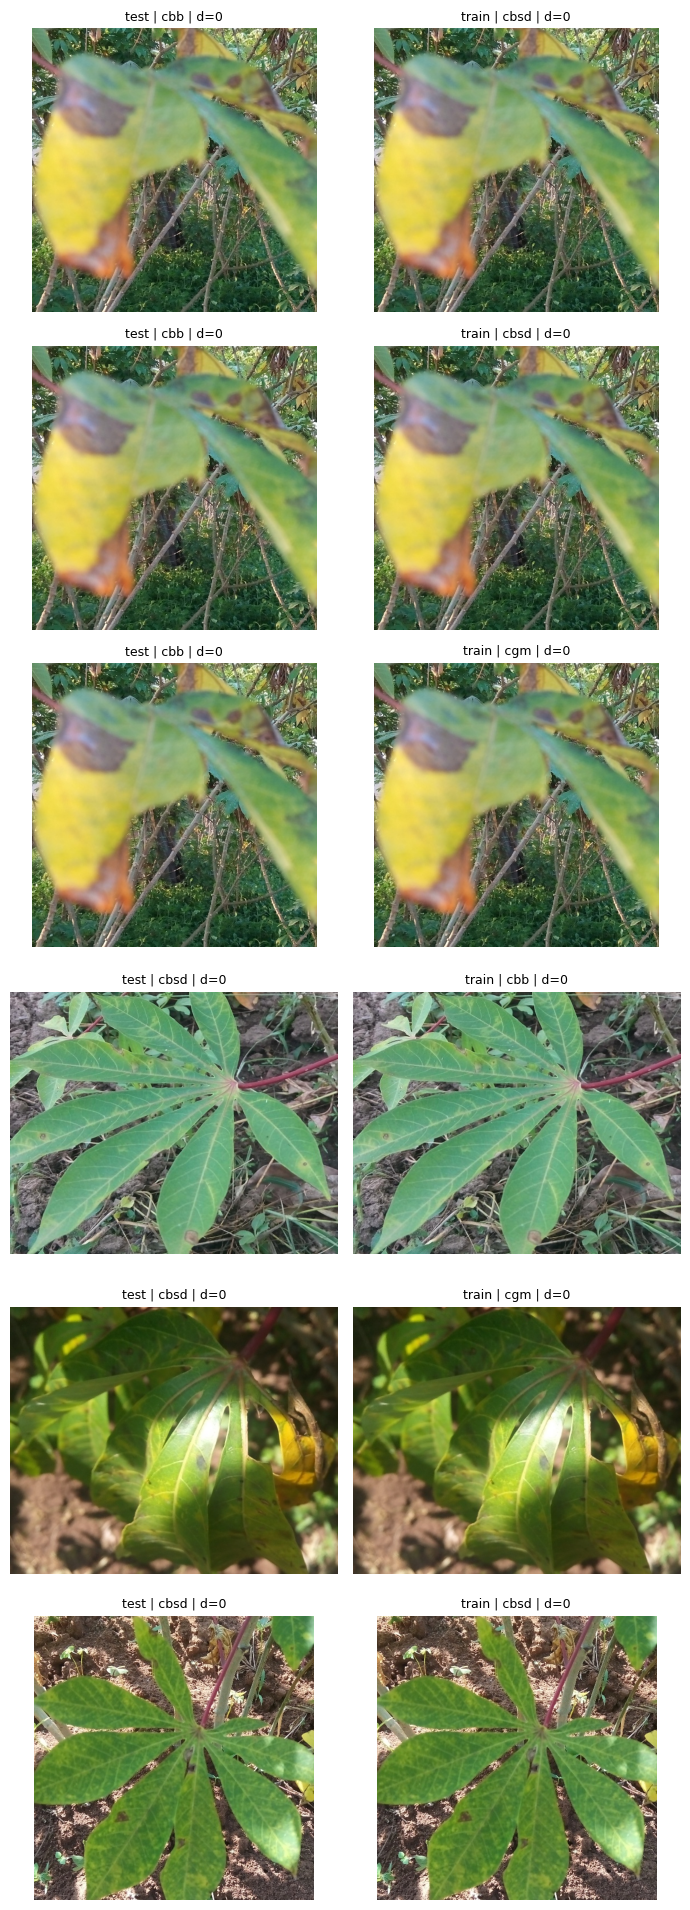

In [14]:
def mostrar_pares(resultados, n=6):
    n = min(n, len(resultados))
    if n == 0:
        print("No hay pares para mostrar con este umbral.")
        return
    fig, axes = plt.subplots(n, 2, figsize=(7, 3.2 * n), squeeze=False)
    for fila, r in enumerate(resultados[:n]):
        for col, lado in enumerate(["a", "b"]):
            axes[fila, col].imshow(Image.open(r[f"ruta_{lado}"]))
            axes[fila, col].set_title(f"{r[f'particion_{lado}']} | {r[f'clase_{lado}']} | d={r['distancia']}", fontsize=9)
            axes[fila, col].axis("off")
    plt.tight_layout()
    plt.savefig(f"docs/evidencias/05_pares_duplicados_umbral{UMBRAL}.png", dpi=100)
    plt.show()

mostrar_pares(resultados)

In [15]:
# Grupos de duplicados exactos: cuántas imágenes, en qué particiones y con qué etiquetas
grupos = dup_exactos.groupby("md5").agg(
    n_imagenes=("ruta", "size"),
    particiones=("split", lambda s: ", ".join(sorted(set(s)))),
    clases=("clase", lambda s: ", ".join(sorted(set(s)))),
    n_clases=("clase", "nunique"))

cruzan = grupos.particiones.str.contains(",")
print("Grupos de duplicados exactos:", len(grupos))
print("Grupos con etiquetas distintas:", int((grupos.n_clases > 1).sum()))
print("Grupos que cruzan particiones:", int(cruzan.sum()))
print("Cruzan particiones Y tienen etiquetas distintas:", int(((grupos.n_clases > 1) & cruzan).sum()))
grupos.to_csv("results/grupos_duplicados_exactos.csv")

# Cuántas imágenes de cada partición de evaluación tienen copia en otra
md5_train = set(df[df.split == "train"].md5)
md5_val = set(df[df.split == "validation"].md5)
test = df[df.split == "test"]
val = df[df.split == "validation"]
print("\nImágenes de test con copia exacta en train:", int(test.md5.isin(md5_train).sum()))
print("Imágenes de test con copia exacta en validation:", int(test.md5.isin(md5_val).sum()))
print("Imágenes de validation con copia exacta en train:", int(val.md5.isin(md5_train).sum()))

# ¿Los pares de pHash son los mismos que los de MD5, o pHash encontró otros?
r = pd.DataFrame(resultados)
md5_de = dict(zip(df.ruta, df.md5))
r["mismo_md5"] = [md5_de[a] == md5_de[b] for a, b in zip(r.ruta_a, r.ruta_b)]
print("\nPares pHash que también son copias exactas (MD5):")
print(r.mismo_md5.value_counts())
print("Pares pHash con etiquetas distintas:", int((r.clase_a != r.clase_b).sum()), "de", len(r))

grupos.sort_values("n_imagenes", ascending=False).head(20)

Grupos de duplicados exactos: 26
Grupos con etiquetas distintas: 18
Grupos que cruzan particiones: 17
Cruzan particiones Y tienen etiquetas distintas: 13

Imágenes de test con copia exacta en train: 11
Imágenes de test con copia exacta en validation: 4
Imágenes de validation con copia exacta en train: 12

Pares pHash que también son copias exactas (MD5):
mismo_md5
True     32
False     4
Name: count, dtype: int64
Pares pHash con etiquetas distintas: 30 de 36


,n_imagenes,particiones,clases,n_clases
md5,,,,
7b12fe4cc1f059bbb2f9b0625ddbc953,4,"test, train","cbb, cbsd, cgm",3
206e79f52dbb5506358c47890dba99ef,3,train,"cbb, cbsd, cgm",3
47d71ffe224d9421a282930db4c8c8ca,3,train,"cbb, cbsd, cgm",3
41dbd73c8823c0992268fd1a2c92653b,3,"test, train, validation","cbb, cbsd, cgm",3
70562f0b471bfb021e4da930fdff23e8,3,"test, train, validation","cbb, cbsd, cgm",3
ed685499c879c39464b16c3294080aef,3,"test, train, validation","cbb, cbsd, cgm",3
8f43a107f6cc605e747b40fe91c4150f,3,train,"cbb, cbsd, cgm",3
c527aed926895b5d9213faf622ca2637,3,"train, validation","cbb, cbsd, cgm",3
8c676fee84ed698602d2543d702b60ab,3,train,"cbb, cbsd, cgm",3


Imágenes de test afectadas (total): 11
clase
cbsd    5
cgm     5
cbb     1
Name: count, dtype: int64 

Imágenes de validation afectadas (total): 12
clase
cbb     5
cbsd    4
cmd     2
cgm     1
Name: count, dtype: int64


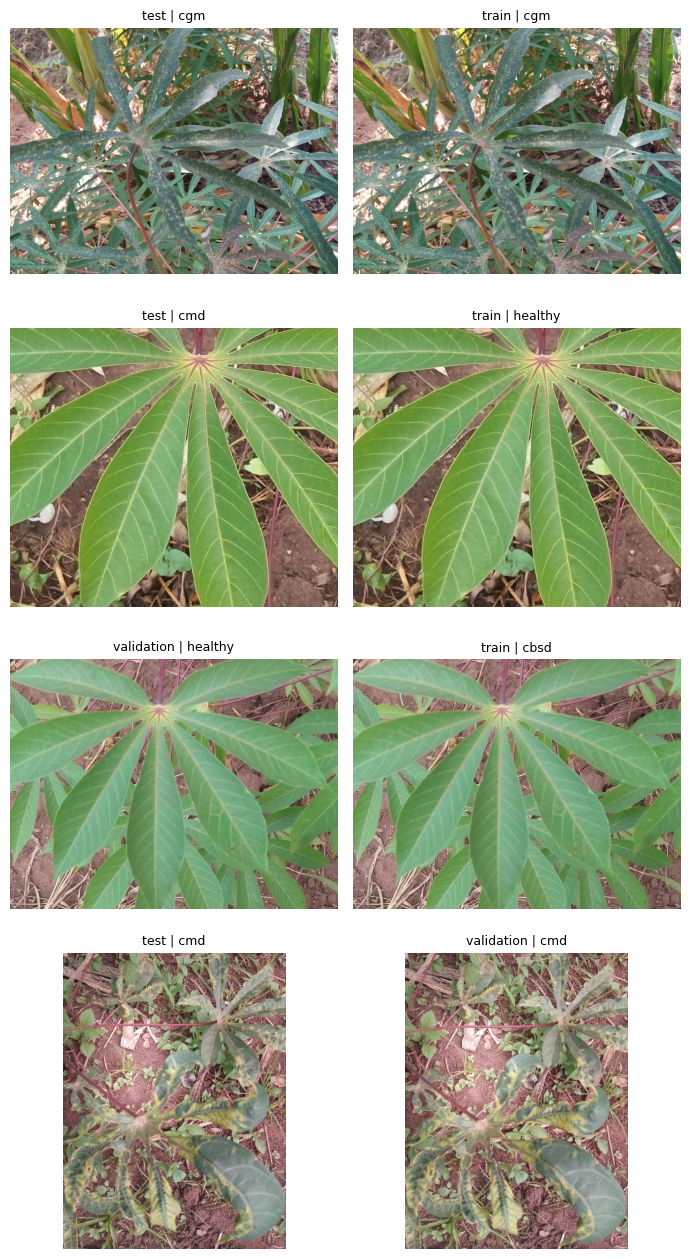

In [16]:
# Imágenes de evaluación con copia exacta en otra partición, por clase
afect_test = test[test.md5.isin(md5_train | md5_val)]
afect_val = val[val.md5.isin(md5_train)]
print("Imágenes de test afectadas (total):", len(afect_test))
print(afect_test.clase.value_counts(), "\n")
print("Imágenes de validation afectadas (total):", len(afect_val))
print(afect_val.clase.value_counts())

# Ver los 4 pares casi idénticos que MD5 no detectó (se guardan en otro archivo)
casi = [x for x, mismo in zip(resultados, r.mismo_md5) if not mismo]
n = len(casi)
fig, axes = plt.subplots(n, 2, figsize=(7, 3.2 * n), squeeze=False)
for fila, p in enumerate(casi):
    for col, lado in enumerate(["a", "b"]):
        axes[fila, col].imshow(Image.open(p[f"ruta_{lado}"]))
        axes[fila, col].set_title(f"{p[f'particion_{lado}']} | {p[f'clase_{lado}']}", fontsize=9)
        axes[fila, col].axis("off")
plt.tight_layout()
plt.savefig("docs/evidencias/06_casi_duplicados_phash.png", dpi=100)
plt.show()

In [17]:
# 1. Agrupar las imágenes que son la misma foto (mismo MD5, o pHash con distancia 0 entre particiones)
padre = list(range(len(df)))

def raiz(i):
    while padre[i] != i:
        padre[i] = padre[padre[i]]
        i = padre[i]
    return i

def unir(i, j):
    padre[raiz(i)] = raiz(j)

for _, idx in df.groupby("md5").groups.items():
    idx = list(idx)
    for k in idx[1:]:
        unir(idx[0], k)

ruta_a_idx = {r: i for i, r in enumerate(df.ruta)}
for p in resultados:
    unir(ruta_a_idx[p["ruta_a"]], ruta_a_idx[p["ruta_b"]])

df["grupo"] = [raiz(i) for i in range(len(df))]

# 2. Aplicar las reglas del protocolo
PRIORIDAD = {"test": 0, "validation": 1, "train": 2}
excluir = {}                                        # índice de la imagen -> motivo

for g, sub in df.groupby("grupo"):
    if len(sub) < 2:
        continue
    if sub.clase.nunique() > 1:                     # Regla 2: etiquetas contradictorias
        for i in sub.index:
            excluir[i] = "etiquetas contradictorias"
    elif sub.split.nunique() > 1:                   # Regla 1: misma etiqueta, cruza particiones
        conservar = min(sub.split, key=PRIORIDAD.get)
        for i in sub.index:
            if sub.split[i] != conservar:
                excluir[i] = f"copia de una imagen en {conservar}"

# 3. Guardar la lista de excluidas y las particiones finales
excl = df.loc[list(excluir)].copy()
excl["motivo"] = [excluir[i] for i in excl.index]
excl[["split", "clase", "ruta", "md5", "motivo"]].to_csv("results/imagenes_excluidas.csv", index=False)

df_final = df.drop(index=list(excluir))
df_final[["split", "clase", "ruta"]].to_csv("results/particiones_finales.csv", index=False)

# 4. Resumen
print("Imágenes excluidas:", len(excl))
print(excl.groupby(["motivo", "split"]).size(), "\n")

antes = df.groupby(["clase", "split"]).size().unstack()[["train", "validation", "test"]]
despues = df_final.groupby(["clase", "split"]).size().unstack()[["train", "validation", "test"]]
print("Excluidas por clase y partición:\n", antes - despues, "\n")
print("Particiones finales:\n", despues)
print("Totales finales:", despues.sum().to_dict())

# 5. Comprobación: ya no debe quedar ninguna copia exacta repartida entre particiones
cruces = df_final.groupby("md5").split.nunique()
print("\nCopias exactas que aún cruzan particiones:", int((cruces > 1).sum()))

Imágenes excluidas: 62
motivo                             split     
copia de una imagen en test        train          2
                                   validation     1
copia de una imagen en validation  train          3
etiquetas contradictorias          test          11
                                   train         35
                                   validation    10
dtype: int64 

Excluidas por clase y partición:
 split    train  validation  test
clase                           
cbb         11           5     1
cbsd        14           3     4
cgm         11           1     5
cmd          3           1     1
healthy      1           1     0 

Particiones finales:
 split    train  validation  test
clase                           
cbb        455         151   154
cbsd      1429         479   477
cgm        762         257   253
cmd       2655         886   885
healthy    315         105   105
Totales finales: {'train': 5616, 'validation': 1878, 'test': 1874}

Copias exactas q

In [18]:
from torchvision import models
print("MobileNetV2:", models.MobileNet_V2_Weights.IMAGENET1K_V1.transforms())
print("ResNet18:   ", models.ResNet18_Weights.IMAGENET1K_V1.transforms())

MobileNetV2: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
ResNet18:    ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [19]:
%%writefile docs/protocolo.md
# Protocolo experimental

## Decisiones ya tomadas

### 1. Duplicados que cruzan particiones
**Decisión:** cuando una misma imagen con la misma etiqueta aparece en dos particiones, se conserva la copia de test (o la de validation si el cruce es con train) y se elimina la otra.
**Justificación:** el conjunto de prueba funciona como el examen final: debe quedar fijo para que todos los experimentos se evalúen con las mismas imágenes y para mantener las particiones oficiales de TFDS. Por eso se quitan las copias de train, que es con lo que el modelo aprende. Así se cumple el requisito de no repartir capturas repetidas entre entrenamiento y prueba.
**Resultado:** 6 imágenes excluidas (5 de train, 1 de validation).

### 2. Imágenes con etiquetas contradictorias
**Decisión:** se excluyen todas las imágenes de los grupos de duplicados con etiquetas distintas, en todas las particiones, incluido test. Esta regla tiene prioridad sobre la decisión 1.
**Justificación:** en la mayoría de esos grupos la misma foto aparece una vez como cbb, otra como cbsd y otra como cgm; no hay etiqueta mayoritaria y no hay forma de saber cuál es la correcta. En train, el modelo aprendería información contradictoria; en test, se evaluaría contra una respuesta que puede estar mal. Posibles causas (no comprobadas, se manejan como hipótesis): error de etiquetado, síntomas parecidos entre enfermedades o una hoja con varias enfermedades.
**Resultado:** 56 imágenes excluidas (35 de train, 10 de validation, 11 de test).
**Limitación:** las exclusiones se concentran en clases minoritarias (cbb, cbsd y cgm), y el test final tiene 11 imágenes menos que el oficial (0,6 %).

### 3. Tamaño de imagen y redimensionamiento
**Decisión:** redimensionar el lado corto a 256 píxeles y recortar el centro a 224×224, igual en train, validation y test y en todos los experimentos.
**Justificación:** es el preprocesamiento oficial de los pesos preentrenados de MobileNetV2 y ResNet18 en torchvision (verificado: resize 256, recorte 224, interpolación bilineal), así que las imágenes llegan al modelo en la forma para la que fue entrenado. No deforma las lesiones, y como todas las imágenes terminan cuadradas sin deformación ni franjas, la proporción de la foto (que varía por clase) no puede servir como atajo.
**Limitación:** se pierden los bordes; en fotos de 888×500 se descarta casi la mitad del ancho. Se revisará en el análisis de errores.

### 4. Detección de duplicados
**Decisión:** MD5 para copias exactas y pHash con umbral 0 para casi duplicados.
**Justificación:** con umbral 0 se detectaron 4 pares casi idénticos adicionales, revisados visualmente. Un umbral mayor podría marcar como duplicadas fotos distintas que solo se parecen.
**Limitación:** pueden quedar fotos de la misma hoja tomadas en momentos distintos que este método no detecta.

### Particiones finales
train 5616 · validation 1878 · test 1874 (archivo: results/particiones_finales.csv; exclusiones con su motivo en results/imagenes_excluidas.csv).

### Normalización
Media [0.485, 0.456, 0.406] y desviación estándar [0.229, 0.224, 0.225] de ImageNet, la que corresponde a ambos backbones.

## Decisiones pendientes (reunión del equipo)
- **Semilla:**
- **Métrica principal:**
- **Presupuesto de entrenamiento** (épocas fijas o early stopping; épocas adicionales de E2):
- **Optimizador y tasa de aprendizaje** (cabeza en E1/E3; tasa menor en E2):
- **Batch size:**
- **Manejo del desbalance:**
- **Criterio de selección del modelo** (mejor época según validación o última época):
- **Tipo de baseline E0:**
- **Número de semillas para estabilidad:**
- **Experimento adicional** (augmentation en train o brillo en una copia de test):

Writing docs/protocolo.md


In [20]:
!git add results docs
!git commit -m "EDA completo: duplicados, exclusiones, particiones finales y protocolo inicial"
!git push

[main bda1246] EDA completo: duplicados, exclusiones, particiones finales y protocolo inicial
 11 files changed, 19038 insertions(+)
 create mode 100644 docs/evidencias/03_distribucion_clases.png
 create mode 100644 docs/evidencias/04_ejemplos_por_clase.png
 create mode 100644 docs/evidencias/05_pares_duplicados_umbral0.png
 create mode 100644 docs/evidencias/06_casi_duplicados_phash.png
 create mode 100644 docs/protocolo.md
 create mode 100644 results/duplicados_exactos.csv
 create mode 100644 results/duplicados_phash_umbral0.csv
 create mode 100644 results/grupos_duplicados_exactos.csv
 create mode 100644 results/imagenes_excluidas.csv
 create mode 100644 results/inventario_imagenes.csv
 create mode 100644 results/particiones_finales.csv
Enumerating objects: 20, done.
Counting objects: 100% (20/20), done.
Delta compression using up to 2 threads
Compressing objects: 100% (16/16), done.
Writing objects: 100% (16/16), 5.26 MiB | 7.84 MiB/s, done.
Total 16 (delta 4), reused 0 (delta 0), 